<a href="https://colab.research.google.com/github/williamsalazar0607/entregar/blob/main/entregar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Error Cuadrático Medio (MSE): 0.0975
Coeficiente de Determinación (R^2): 0.8421

Con los datos ingresados, el precio predicho es: $8.64 USD por galón



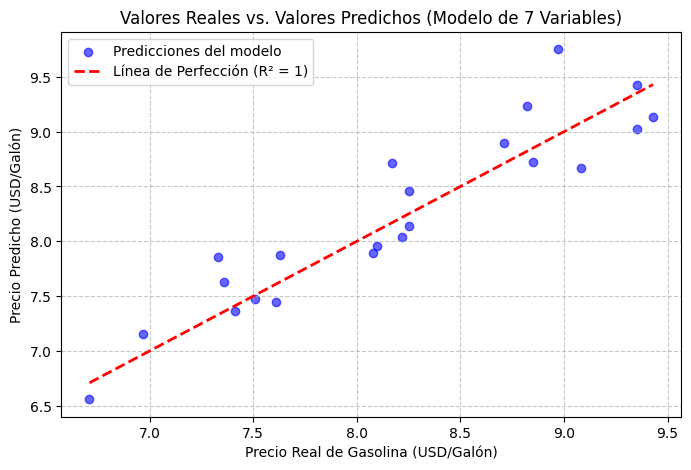

Modelo guardado exitosamente como modelo_gasolina.pkl


In [3]:
# Importamos las bibliotecas necesarias
import joblib

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# 1. Cargar el dataset desde el archivo CSV
df = pd.read_csv("dataset_precio_gasolina.csv")

# 2. Definir las 7 variables independientes óptimas (X) y la dependiente (y)
# Se eliminó "Produccion_OPEP_millones_dia" porque generaba ruido estadístico
X = df[[
    'Precio_Petroleo_USD_Barril',
    'Demanda_miles_barriles_dia',
    'PIB_Porcentaje',
    'Impuestos_Combustibles_Porcentaje',
    'Eventos_Geopoliticos',
    'Tipo_Cambio_USD_COP',
    'Inflacion_Porcentaje'
]]
y = df['Precio_Gasolina_USD_Galon']

# 3. Dividir los datos: 65% entrenamiento, 35% prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

# 4. Crear el modelo de regresión lineal
model = LinearRegression()

# 5. Entrenar el modelo
model.fit(X_train, y_train)

# 6. Predecir y evaluar el modelo
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


print(f"Error Cuadrático Medio (MSE): {mse:.4f}")
print(f"Coeficiente de Determinación (R^2): {r2:.4f}\n")

# 7. Predecir con datos nuevos usando las 7 variables
datos_nuevos = pd.DataFrame({
    'Precio_Petroleo_USD_Barril': [75.0],
    'Demanda_miles_barriles_dia': [9500.0],
    'PIB_Porcentaje': [3.5],
    'Impuestos_Combustibles_Porcentaje': [19.0],
    'Eventos_Geopoliticos': [1],
    'Tipo_Cambio_USD_COP': [4000.0],
    'Inflacion_Porcentaje': [5.0]
})

precio_predicho = model.predict(datos_nuevos)
print(f"Con los datos ingresados, el precio predicho es: ${precio_predicho[0]:.2f} USD por galón\n")

# 8. Gráfico de Valores Reales vs Predichos
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color='blue', alpha=0.6, label='Predicciones del modelo')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', linewidth=2, label='Línea de Perfección (R² = 1)')

plt.title('Valores Reales vs. Valores Predichos (Modelo de 7 Variables)')
plt.xlabel('Precio Real de Gasolina (USD/Galón)')
plt.ylabel('Precio Predicho (USD/Galón)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


archivo_modelo = 'modelo_gasolina.pkl'
joblib.dump(model, archivo_modelo)
print(f"Modelo guardado exitosamente como {archivo_modelo}")